<div align="right">
    <img src="./Imagenes/logo_UTN.svg" alt="Logo de la UTN" width="150" />
</div>

#### Teoría de los Circuitos II
# Trabajo Semanal 9
#### Alumno: Lucas Gallero
#### Profesor: Mariano Llamedo Soria
#### Ayudante de TPs: David Moharos
----

# Enunciado

**1)** Dada la siguiente **transferencia de tensión:**

<div align="center">
    <img src="./Imagenes/Enunciado1.png" alt="Circuito del enunciado 1" width="430" />
</div>

$$T(s)=\frac{V_2}{V_g}=k\cdot\frac{s\cdot\left(s^2+\frac{1}{16}\right)}{s^3+2\cdot s^2+2\cdot s+1}$$

**a)** Sintetizar el cuadripolo pasivo sin pérdidas.

**b)** Hallar el valor de $k$ que cumple con la síntesis y el valor de los componentes hallados.

<br>

**2)** Dada la siguiente **transimpedancia:**

<div align="center">
    <img src="./Imagenes/Enunciado2.png" alt="Circuito del enunciado 2" width="430" />
</div>

$$T(s)=\frac{V_2}{I_1}=k\cdot\frac{s^2+9}{s^3+2\cdot s^2+2\cdot s+1}$$

**a)** Sintetizar el cuadripolo pasivo sin pérdidas.

**b)** Hallar el valor de $k$ que cumple con la síntesis y valor de los componentes hallados.

<br>

**3)** Dada la siguiente **transimpedancia:**

<div align="center">
    <img src="./Imagenes/Enunciado3.png" alt="Circuito del enunciado 3" width="430" />
</div>

$$T(s)=\frac{V_2}{I_g}=k\cdot\frac{s\cdot\left(s^2+\frac{1}{16}\right)}{s^3+2\cdot s^2+2\cdot s+1}$$

**a)** Sintetizar el cuadripolo pasivo sin pérdidas.

**b)** Hallar el valor de $k$ para obtener **-6 dB** en el centro de la banda de paso.

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from pytc2.general import s, print_latex, a_equal_b_latex_s
from pytc2.remociones import remover_polo_dc, remover_polo_infinito, remover_polo_jw
from pytc2.cuadripolos import TabcdZ_s, TabcdY_s

%matplotlib inline
sp.init_printing()
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'figure.dpi': 100})

Q = s**3+2*s**2+2*s+1
P = s*(s**2+sp.Rational(1,16))
f = np.logspace(-4, 3, 7001)

def mostrar(nombre, expresion):
    print_latex(a_equal_b_latex_s(nombre, sp.factor(expresion)))

def graficar_transferencia(numero, funcion, omega_cero):
    h = np.asarray(sp.lambdify(s, funcion, 'numpy')(2j*np.pi*f), dtype=complex)
    fz = float(omega_cero)/(2*np.pi)
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
    ax[0].semilogx(f, 20*np.log10(np.maximum(abs(h), 1e-16)), color='black')
    ax[1].semilogx(f, np.degrees(np.unwrap(np.angle(h))), color='tab:blue')
    ax[0].set_title(f'Ejercicio {numero} - Transferencia en Python')
    ax[0].set_ylabel('Módulo (dB)' if numero == 1 else 'Módulo (dB ref. 1 Ω)')
    ax[1].set_ylabel('Fase (°)')
    ax[1].set_xlabel('Frecuencia (Hz)')
    for eje in ax:
        eje.grid(True, which='both', alpha=.3)
        eje.axvline(fz, color='gray', ls=':', lw=1)
    plt.show()

def graficar_parametros(numero, excitacion, transferencia):
    nombre = 'Z_{22}' if numero == 2 else 'Z_{11}'
    fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
    for eje, funcion, etiqueta, color in [
        (ax[0], transferencia, 'Z_{21}', 'red'),
        (ax[1], excitacion, nombre, 'blue')
    ]:
        h = np.asarray(sp.lambdify(s, funcion, 'numpy')(2j*np.pi*f), dtype=complex)
        eje.semilogx(f, 20*np.log10(np.maximum(abs(h), 1e-16)), color=color)
        eje.set_ylabel('$'+etiqueta+'$ (dB ref. 1 Ω)')
        eje.grid(True, which='both', alpha=.3)
    ax[0].set_title(f'Ejercicio {numero} - Parámetros del cuadripolo en Python')
    ax[1].set_xlabel('Frecuencia (Hz)')
    plt.show()

---
# <ins>Resolución</ins>

## <ins>Criterio de síntesis y normalización</ins>

Se adopta $R_g=1\;\Omega$ en los ejercicios 1 y 3, y $R_L=1\;\Omega$ en el ejercicio 2. Los componentes se expresan para una norma de frecuencia $\Omega_0=1\;\mathrm{rad/s}$. Para otras normas: $L=R_0L_n/\Omega_0$ y $C=C_n/(R_0\Omega_0)$.

El denominador común se separa en parte par e impar:

$$Q(s)=M(s)+N(s),\qquad M(s)=2s^2+1,\qquad N(s)=s(s^2+2).$$

Se escribe la transferencia como $F_T/(1+F_E)$, eligiendo la división que deje un parámetro transferencia impar. Si el numerador prescrito es impar se divide por $M$; si es par, por $N$.

Los mapas muestran el semieje $j\omega$ positivo. Los puntos finitos no nulos tienen sus conjugados en el semieje negativo. Los círculos verdes son ceros y las cruces rojas, polos; RP y RT indican remoción parcial y total. Los círculos verdes discontinuos señalan cancelaciones, no ceros que permanezcan en el resto.

Para las remociones se invierte la función de excitación bajo su condición de medición: se usa $Y_0=1/Z_{11}$ con $I_2=0$ en los ejercicios 1 y 3, y $Y_0=1/Z_{22}$ con $I_1=0$ en el ejercicio 2. $Y_0$ es una función auxiliar de síntesis, no un parámetro de la matriz de admitancias. La conversión entre matrices es $\mathbf{Y}=\mathbf{Z}^{-1}$; no se obtiene invirtiendo cada parámetro por separado.


## <ins>1. Transferencia de tensión con salida abierta</ins>

$$T(s)=\frac{V_2}{V_g}=k\cdot\frac{s\cdot\left(s^2+\frac{1}{16}\right)}{s^3+2\cdot s^2+2\cdot s+1}$$

### <ins>Relación entre la transferencia y los parámetros Z</ins>

Con $I_2=0$:

$$V_1=Z_{11}I_1,\qquad V_2=Z_{21}I_1,\qquad V_g=(R_g+Z_{11})I_1.$$

$$\boxed{T_1=\frac{Z_{21}}{R_g+Z_{11}}}.$$

Para $R_g=1$, se divide por la parte par de $Q$:

$$T_1=\frac{\displaystyle k\frac{s(s^2+1/16)}{2s^2+1}}
{\displaystyle 1+\frac{s(s^2+2)}{2s^2+1}}.$$

$$\boxed{Z_{11}=\frac{s(s^2+2)}{2s^2+1}},\qquad
Z_{21}=k\frac{s(s^2+1/16)}{2s^2+1}.$$

In [2]:
Rg1 = sp.Integer(1)
Z11_1 = s*(s**2+2)/(2*s**2+1)
Z21_base1 = P/(2*s**2+1)
mostrar('Z_{11}', Z11_1)
mostrar('Z_{21}/k', Z21_base1)
assert sp.cancel(Z21_base1/(1+Z11_1)-P/Q) == 0

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Mapa de remociones</ins>

<div align="center">
    <img src="./Imagenes/TS9_mapa_remociones_1.png" alt="Mapa de remociones del ejercicio 1" width="600" />
</div>

### <ins>Primera remoción: inductor L1 en derivación</ins>

Se invierte la impedancia de entrada, conservando la condición $I_2=0$:

$$Y_0=\frac{1}{Z_{11}}=\frac{2s^2+1}{s(s^2+2)}.$$

Para obtener el cero de transmisión en $\omega_z=1/4$, se remueve parcialmente el polo en el origen. El coeficiente se calcula evaluando en $s^2=-1/16$:

$$K_0=\left.sY_0\right|_{s^2=-1/16}
=\frac{1-2/16}{2-1/16}=\frac{14}{31}.$$

$$Y_{L_1}=\frac{K_0}{s}=\frac1{sL_1}
\quad\Longrightarrow\quad\boxed{L_1=\frac{31}{14}\;\mathrm H}.$$

$$Y_2=Y_0-\frac{14}{31s}
=\boxed{\frac{48}{31}\frac{s^2+1/16}{s(s^2+2)}}.$$

In [3]:
Y0_1 = sp.cancel(1/Z11_1)
mostrar('Y_0=1/Z_{11}', Y0_1)
Y2_1, YL1_1 = remover_polo_dc(Y0_1, omega_zero=sp.Rational(1,4))
L1_1 = sp.cancel(1/(s*YL1_1))
Z2_1 = sp.cancel(1/Y2_1)
mostrar('Y_{L_1}', YL1_1)
mostrar('Y_2', Y2_1)
mostrar('Z_2', Z2_1)
assert sp.cancel(Y0_1-YL1_1-Y2_1) == 0
assert sp.cancel(Y2_1.subs(s,sp.I/4)) == 0

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Segunda remoción: tanque LC paralelo en serie</ins>

Al invertir $Y_2$ aparece el polo que se necesita remover:

$$Z_2=\frac{31}{48}\frac{s(s^2+2)}{s^2+1/16}.$$

Se extrae el término $Z_t=A_ts/(s^2+1/16)$, con

$$A_t=\left.\frac{s^2+1/16}{s}Z_2\right|_{s^2=-1/16}
=\frac{31}{48}\left(2-\frac1{16}\right)=\frac{961}{768}.$$

Un tanque LC paralelo tiene $Z_t=(1/C_2)s/[s^2+1/(L_2C_2)]$. Por comparación:

$$\boxed{C_2=\frac{768}{961}\;\mathrm F},\qquad
\boxed{L_2=\frac{961}{48}\;\mathrm H}.$$

### <ins>Tercera remoción: inductor de cierre</ins>

$$Z_4=Z_2-Z_t=\frac{31}{48}s,\qquad Y_4=\frac{48}{31s}.$$

La remoción total del polo en el origen de $Y_4$ deja $Y_6=0$:

$$\boxed{L_3=\frac{31}{48}\;\mathrm H}.$$

$L_3$ pertenece al cuadripolo y se conserva aunque la salida esté abierta.

In [4]:
Z4_1, Zt_1, L2_1, C2_1 = remover_polo_jw(Z2_1, omega=sp.Rational(1,4), isImpedance=True)
Y4_1 = sp.cancel(1/Z4_1)
Y6_1, YL3_1 = remover_polo_dc(Y4_1)
L3_1 = sp.cancel(1/(s*YL3_1))
mostrar('Z_t', Zt_1)
mostrar('Z_4', Z4_1)
mostrar('Y_6', Y6_1)
for nombre, valor, unidad in [('L1',L1_1,'H'),('L2',L2_1,'H'),('C2',C2_1,'F'),('L3',L3_1,'H')]:
    print(f'{nombre}: {sp.sstr(valor)} = {float(valor):.10g} {unidad}')
assert sp.cancel(Y6_1) == 0
assert L2_1*C2_1 == 16

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

L1: 31/14 = 2.214285714 H
L2: 961/48 = 20.02083333 H
C2: 768/961 = 0.7991675338 F
L3: 31/48 = 0.6458333333 H


### <ins>Cálculo de k desde el circuito sintetizado</ins>

Con $I_2=0$, la corriente de la rama del tanque se obtiene por divisor de corriente. Así:

$$Z_{21,\mathrm{red}}=\frac{V_2}{I_1}
=\frac{(sL_1)(sL_3)}{sL_1+Z_t+sL_3}
=\frac{s(s^2+1/16)}{2s^2+1}.$$

Al compararlo con el parámetro prescrito se obtiene $\boxed{k_1=1}$.

También se comprueba a alta frecuencia: el capacitor puentea el tanque y las derivaciones inductivas presentan impedancia creciente; la corriente por $R_g$ tiende a cero y $V_2/V_g\to1$.

In [5]:
Z21_red1 = sp.cancel((s*L1_1)*(s*L3_1)/(s*L1_1+Zt_1+s*L3_1))
k1 = sp.cancel(Z21_red1/Z21_base1)
Y_red1 = sp.Matrix([
    [1/(s*L1_1)+1/Zt_1, -1/Zt_1],
    [-1/Zt_1, 1/(s*L3_1)+1/Zt_1]
])
Z_red1 = Y_red1.inv().applyfunc(sp.factor)
T1 = sp.cancel(Z_red1[1,0]/(Rg1+Z_red1[0,0]))
M1 = TabcdZ_s(Rg1)*TabcdY_s(1/(s*L1_1))*TabcdZ_s(Zt_1)*TabcdY_s(1/(s*L3_1))
mostrar('k_1', k1)
mostrar('T_1', T1)
assert sp.cancel(Z_red1[0,0]-Z11_1) == 0
assert sp.cancel(Z_red1[1,0]-Z21_red1) == 0
assert sp.cancel(T1-P/Q) == 0
assert sp.cancel(1/M1[0,0]-T1) == 0
assert all(x>0 for x in [L1_1,L2_1,C2_1,L3_1])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Circuito obtenido</ins>

<div align="center">
    <img src="./Imagenes/circuito_punto_1.png" alt="Circuito LC del ejercicio 1" width="800" />
</div>

### <ins>Puntos de verificación</ins>

$$T_1(0)=0,\qquad T_1(j/4)=0,\qquad T_1(\infty)=1.$$

$Z_{11}$ tiene polos en $0{,}707107\;\mathrm{rad/s}$ e infinito, y ceros en el origen y $\sqrt2\;\mathrm{rad/s}$. $Z_{21}$ tiene los mismos polos, con ceros en el origen y $1/4\;\mathrm{rad/s}$. Los polos de la función de excitación pertenecen al cuadripolo sin la resistencia externa; no son los polos de la transferencia cargada.

In [6]:
mostrar('T_1(0)', sp.limit(T1,s,0))
mostrar('T_1(j/4)', sp.simplify(T1.subs(s,sp.I/4)))
mostrar(r'T_1(\infty)', sp.limit(T1,s,sp.oo))
assert sp.limit(T1,s,0)==0 and sp.limit(T1,s,sp.oo)==1

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Curvas en Python</ins>

Se grafica el módulo y la fase de la transferencia obtenida, seguido de las curvas de $Z_{21}$ y $Z_{11}$ del cuadripolo LC. La frecuencia se expresa en Hz, con $f=\omega/(2\pi)$.

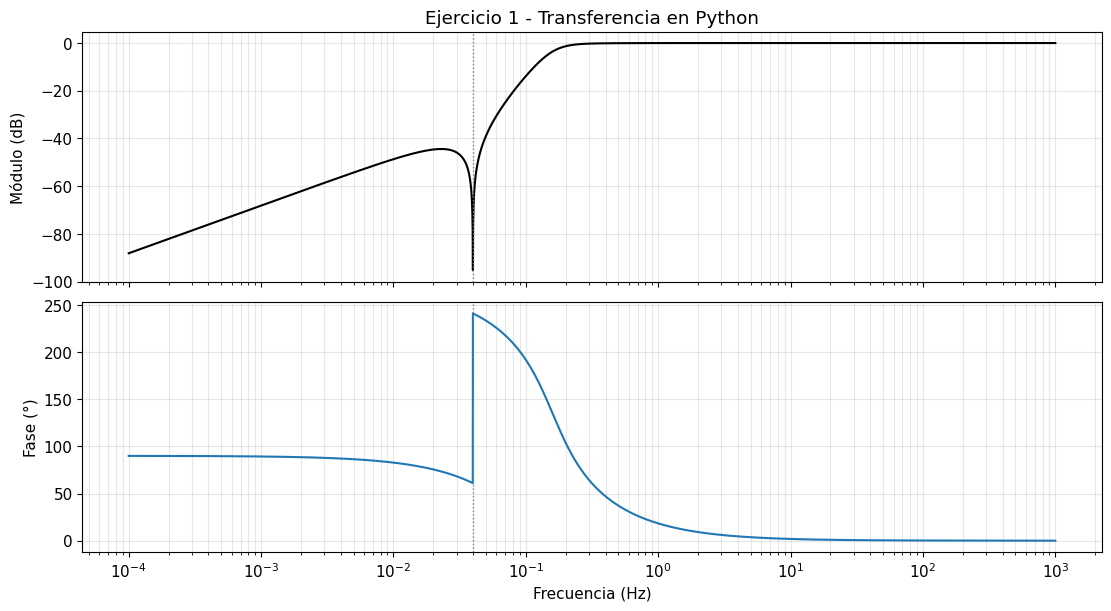

In [7]:
graficar_transferencia(1, T1, sp.Rational(1,4))

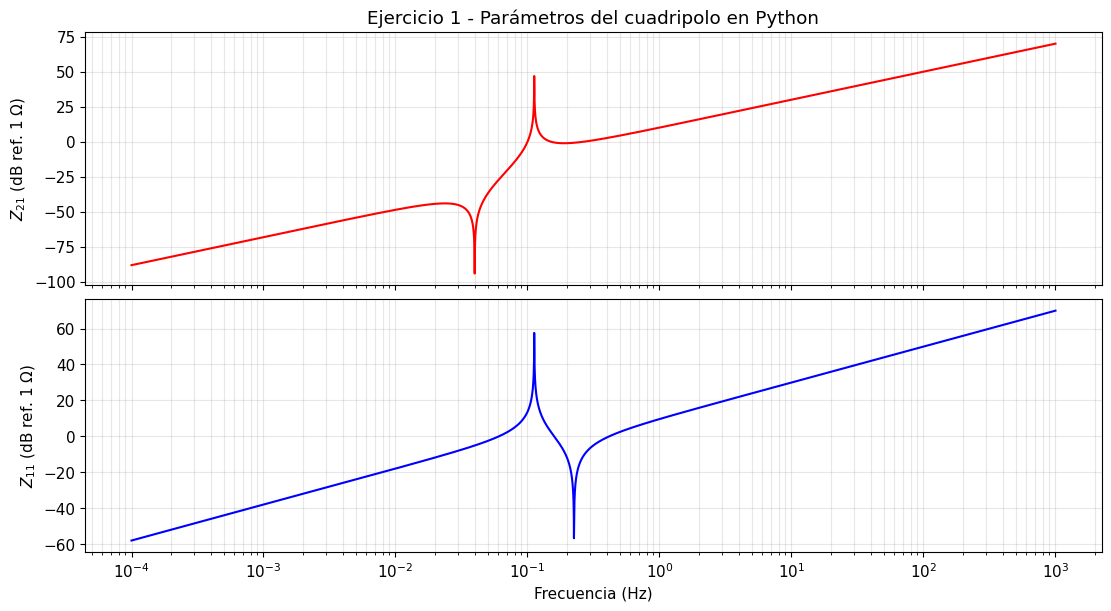

In [8]:
graficar_parametros(1, Z11_1, Z21_red1)

### <ins>Simulación en LTspice</ins>

Se simula el circuito con $R_g=1\;\Omega$ y la salida abierta. La transferencia se mide como `V(V2)/V(Vg)`.

<div align="center">
    <img src="./Imagenes/Ej1 Simulacion Circuito.png" alt="Circuito simulado del ejercicio 1" width="760" style="max-width:100%; height:auto;" />
</div>

#### Módulo y fase de la transferencia

<div align="center">
    <img src="./Imagenes/Ej1 Simulacion Modulo y Fase.png" alt="Módulo y fase de la transferencia del ejercicio 1 en LTspice" width="1100" style="max-width:100%; height:auto;" />
</div>

#### Parámetros del cuadripolo

Las curvas siguientes corresponden a $Z_{21}$ y $Z_{11}$ del cuadripolo LC, sin incluir $R_g$.

<div align="center">
    <img src="./Imagenes/Ej1 Simulacion Z21 Z11.png" alt="Z21 y Z11 del ejercicio 1 en LTspice" width="1100" style="max-width:100%; height:auto;" />
</div>

Los cursores ubican el cero de $Z_{21}$ cerca de $0{,}0398\;\mathrm{Hz}$, el polo común cerca de $0{,}1125\;\mathrm{Hz}$ y el cero de $Z_{11}$ cerca de $0{,}2251\;\mathrm{Hz}$.

<div align="center">
    <img src="./Imagenes/Ej1 Simulacion PoloCero Z21.png" alt="Lecturas de los cursores para Z21 del ejercicio 1" width="290" />
    <img src="./Imagenes/Ej1 Simulacion PoloCero Z11.png" alt="Lecturas de los cursores para Z11 del ejercicio 1" width="290" />
</div>

### <ins>Conclusión</ins>

Las curvas de Python y la simulación en LTspice muestran el nulo de transmisión en $\omega_z=1/4\;\mathrm{rad/s}$, equivalente a $f_z\approx0{,}03979\;\mathrm{Hz}$, y una transferencia que tiende a $1$ ($0\;\mathrm{dB}$) a alta frecuencia. Los polos y ceros observados en $Z_{11}$ y $Z_{21}$ coinciden con las funciones usadas en la síntesis. Se verifica así el circuito obtenido con $k_1=1$.

---
## <ins>2. Transimpedancia con carga en la salida</ins>

$$T(s)=\frac{V_2}{I_1}=k\cdot\frac{s^2+9}{s^3+2\cdot s^2+2\cdot s+1}$$

### <ins>Relación entre la transferencia y los parámetros Z</ins>

$$V_2=Z_{21}I_1+Z_{22}I_2,\qquad I_2=-V_2/R_L.$$

$$V_2\left(1+\frac{Z_{22}}{R_L}\right)=Z_{21}I_1
\quad\Longrightarrow\quad
\boxed{T_2=\frac{Z_{21}}{1+Z_{22}/R_L}}.$$

Con $R_L=1$ y numerador par, se divide por $N=s(s^2+2)$:

$$\boxed{Z_{22}=\frac{2s^2+1}{s(s^2+2)}},\qquad
Z_{21}=k\frac{s^2+9}{s(s^2+2)}.$$

La síntesis se realiza desde el puerto 2 hacia el puerto 1. La condición para medir $Z_{22}$ es $I_1=0$: la entrada queda abierta y $R_L$ se retira.

In [9]:
RL2 = sp.Integer(1)
Z22_2 = (2*s**2+1)/(s*(s**2+2))
Z21_base2 = (s**2+9)/(s*(s**2+2))
mostrar('Z_{22}', Z22_2)
mostrar('Z_{21}/k', Z21_base2)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Mapa de remociones</ins>

<div align="center">
    <img src="./Imagenes/TS9_mapa_remociones_2.png" alt="Mapa de remociones del ejercicio 2" width="750" />
</div>

### <ins>Primera remoción: capacitor C1 en la salida</ins>

$$Y_0=\frac{1}{Z_{22}}=\frac{s(s^2+2)}{2s^2+1}.$$

Se remueve parcialmente el polo en infinito para crear un cero en $\omega_z=3$:

$$C_1=\left.\frac{Y_0}s\right|_{s^2=-9}
=\frac{-9+2}{2(-9)+1}=\boxed{\frac7{17}\;\mathrm F}.$$

$$Y_2=Y_0-\frac7{17}s
=\boxed{\frac{3s(s^2+9)}{17(2s^2+1)}}.$$

### <ins>Segunda remoción: tanque LC paralelo</ins>

$$Z_2=\frac1{Y_2}=\frac{17(2s^2+1)}{3s(s^2+9)}.$$

$$A_t=\left.\frac{s^2+9}{s}Z_2\right|_{s^2=-9}
=\left.\frac{17(2s^2+1)}{3s^2}\right|_{s^2=-9}=\frac{289}{27}.$$

$$Z_t=\frac{289}{27}\frac{s}{s^2+9},\qquad
\boxed{C_2=\frac{27}{289}\;\mathrm F},\qquad
\boxed{L_2=\frac{289}{243}\;\mathrm H}.$$

### <ins>Tercera remoción: capacitor de cierre en la entrada</ins>

$$Z_4=Z_2-Z_t=\frac{17}{27s},\qquad Y_4=\frac{27}{17}s.$$

La remoción total del polo en infinito de $Y_4$ deja $Y_6=0$ y da:

$$\boxed{C_3=\frac{27}{17}\;\mathrm F}.$$

In [10]:
Y0_2 = sp.cancel(1/Z22_2)
mostrar('Y_0=1/Z_{22}', Y0_2)
Y2_2, YC1_2 = remover_polo_infinito(Y0_2,omega_zero=3)
C1_2 = sp.cancel(YC1_2/s)
Z2_2 = sp.cancel(1/Y2_2)
Z4_2, Zt_2, L2_2, C2_2 = remover_polo_jw(Z2_2,omega=3,isImpedance=True)
Y4_2 = sp.cancel(1/Z4_2)
Y6_2, YC3_2 = remover_polo_infinito(Y4_2)
C3_2 = sp.cancel(YC3_2/s)
for nombre,expresion in [('Y_2',Y2_2),('Z_2',Z2_2),('Z_t',Zt_2),('Z_4',Z4_2),('Y_6',Y6_2)]:
    mostrar(nombre,expresion)
for nombre, valor, unidad in [('C1 (salida)',C1_2,'F'),('L2',L2_2,'H'),('C2',C2_2,'F'),('C3 (entrada)',C3_2,'F')]:
    print(f'{nombre}: {sp.sstr(valor)} = {float(valor):.10g} {unidad}')
assert sp.cancel(Y0_2-YC1_2-Y2_2) == 0
assert sp.cancel(Z2_2-Zt_2-Z4_2) == 0
assert sp.cancel(Y6_2) == 0
assert L2_2*C2_2 == sp.Rational(1,9)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

C1 (salida): 7/17 = 0.4117647059 F
L2: 289/243 = 1.189300412 H
C2: 27/289 = 0.09342560554 F
C3 (entrada): 27/17 = 1.588235294 F


### <ins>Cálculo de k desde el circuito</ins>

Retirando $R_L$ y dejando la salida abierta:

$$Z_{21,\mathrm{red}}=\frac{Z_{C_3}Z_{C_1}}{Z_{C_3}+Z_t+Z_{C_1}}
=\frac{s^2+9}{9s(s^2+2)}.$$

La comparación con el parámetro prescrito da $\boxed{k_2=1/9}$.

Con la carga conectada, también se puede calcular en continua: los capacitores abren y el inductor une ambos puertos. Toda la corriente circula por $R_L=1$, por lo que $T_2(0)=1=9k_2$.

In [11]:
ZCentrada2 = 1/(s*C3_2)
ZCsalida2 = 1/(s*C1_2)
Z21_red2 = sp.cancel(ZCentrada2*ZCsalida2/(ZCentrada2+Zt_2+ZCsalida2))
k2 = sp.cancel(Z21_red2/Z21_base2)
Y_red2 = sp.Matrix([
    [s*C3_2+1/Zt_2, -1/Zt_2],
    [-1/Zt_2, s*C1_2+1/Zt_2]
])
Z_red2 = Y_red2.inv().applyfunc(sp.factor)
T2 = sp.cancel(Z_red2[1,0]/(1+Z_red2[1,1]/RL2))
M2 = TabcdY_s(s*C3_2)*TabcdZ_s(Zt_2)*TabcdY_s(s*C1_2+1/RL2)
mostrar('k_2',k2)
mostrar('T_2',T2)
assert sp.cancel(Z_red2[1,1]-Z22_2) == 0
assert sp.cancel(Z_red2[1,0]-Z21_red2) == 0
assert sp.cancel(T2-(s**2+9)/(9*Q)) == 0
assert sp.cancel(1/M2[1,0]-T2) == 0
assert all(x>0 for x in [C1_2,L2_2,C2_2,C3_2])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Circuito obtenido</ins>

<div align="center">
    <img src="./Imagenes/circuito_punto_2.png" alt="Circuito LC del ejercicio 2" width="900" />
</div>

La numeración sigue el orden de extracción: $C_1=7/17$ queda en la salida y $C_3=27/17$ en la entrada. Esta ubicación es necesaria para conservar el $Z_{22}$ prescrito; intercambiarlos mantiene $Z_{21}$ por reciprocidad, pero modifica $Z_{22}$ y la transferencia cargada.

### <ins>Puntos de verificación</ins>

$$T_2(0)=1,\qquad T_2(j3)=0,\qquad T_2(\infty)=0.$$

$Z_{22}$ tiene polos en el origen y $\sqrt2\;\mathrm{rad/s}$, y ceros en $1/\sqrt2\;\mathrm{rad/s}$ e infinito. $Z_{21}$ conserva esos polos y tiene ceros en $3\;\mathrm{rad/s}$ e infinito.

In [12]:
mostrar('T_2(0)',sp.limit(T2,s,0))
mostrar('T_2(j3)',sp.simplify(T2.subs(s,3*sp.I)))
mostrar(r'T_2(\infty)',sp.limit(T2,s,sp.oo))
assert sp.limit(T2,s,0)==1 and sp.limit(T2,s,sp.oo)==0

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Curvas en Python</ins>

Se grafica el módulo y la fase de la transferencia obtenida, seguido de las curvas de $Z_{21}$ y $Z_{22}$ del cuadripolo LC. La frecuencia se expresa en Hz, con $f=\omega/(2\pi)$.

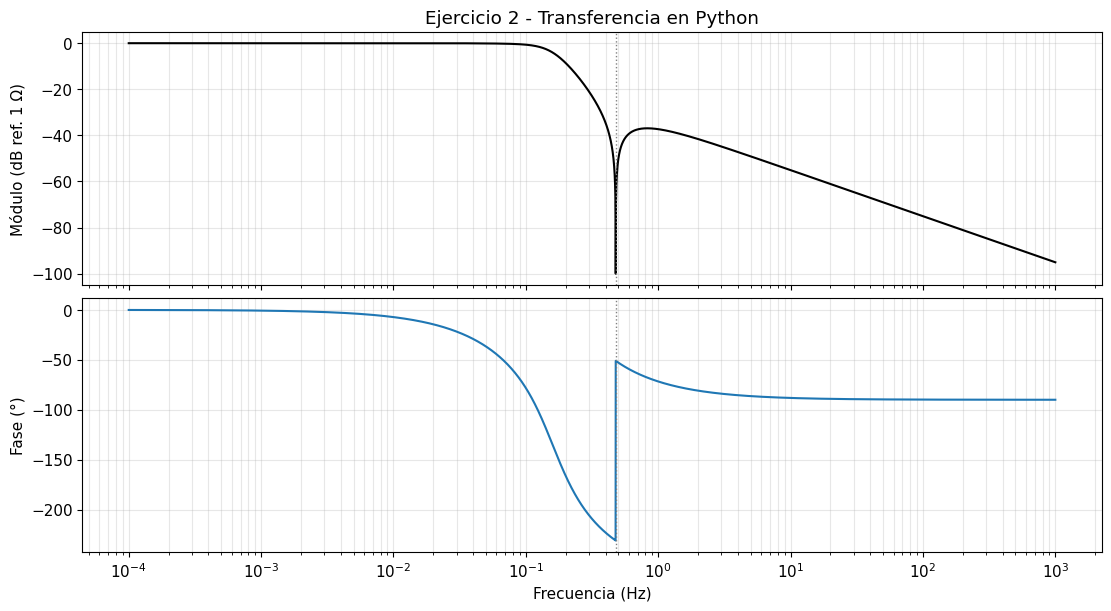

In [13]:
graficar_transferencia(2, T2, 3)

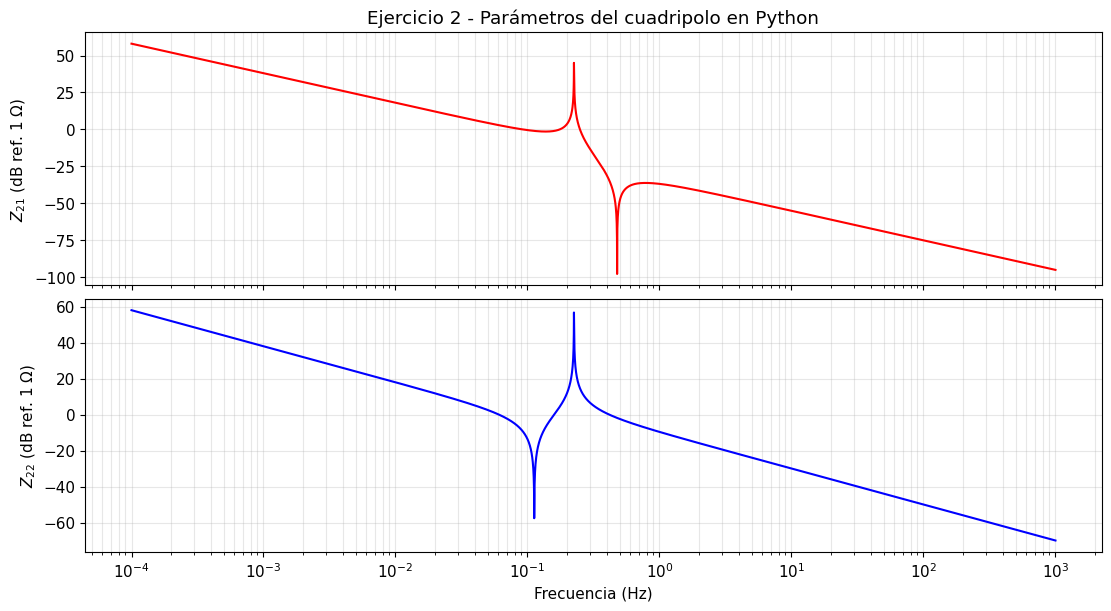

In [14]:
graficar_parametros(2, Z22_2, Z21_red2)

### <ins>Simulación en LTspice</ins>

Se aplica una corriente AC unitaria a la entrada y se conecta $R_L=1\;\Omega$ en la salida. La transimpedancia se mide como `V(V2)/I(I1)`.

<div align="center">
    <img src="./Imagenes/Ej2 Simulacion Circuito.png" alt="Circuito simulado del ejercicio 2" width="900" style="max-width:100%; height:auto;" />
</div>

#### Módulo y fase de la transimpedancia

<div align="center">
    <img src="./Imagenes/Ej2 Simulacion Modulo y Fase.png" alt="Módulo y fase de la transimpedancia del ejercicio 2 en LTspice" width="1100" style="max-width:100%; height:auto;" />
</div>

#### Parámetros del cuadripolo

Se presentan $Z_{21}$ y $Z_{22}$ del cuadripolo LC sin la resistencia de carga.

<div align="center">
    <img src="./Imagenes/Ej2 Simulacion Z21 Z22.png" alt="Z21 y Z22 del ejercicio 2 en LTspice" width="1100" style="max-width:100%; height:auto;" />
</div>

Los cursores muestran el cero de $Z_{22}$ cerca de $0{,}1125\;\mathrm{Hz}$, el polo común cerca de $0{,}2251\;\mathrm{Hz}$ y el cero de $Z_{21}$ cerca de $0{,}4775\;\mathrm{Hz}$.

<div align="center">
    <img src="./Imagenes/Ej2 Simulacion PoloCero Z21.png" alt="Lecturas de los cursores para Z21 del ejercicio 2" width="290" />
    <img src="./Imagenes/Ej2 Simulacion PoloCero Z22.png" alt="Lecturas de los cursores para Z22 del ejercicio 2" width="290" />
</div>

### <ins>Conclusión</ins>

La simulación en LTspice reproduce la respuesta calculada en Python: la transimpedancia tiende a $1\;\Omega$ a baja frecuencia, se anula en $\omega_z=3\;\mathrm{rad/s}$ ($f_z\approx0{,}47746\;\mathrm{Hz}$) y cae a alta frecuencia con una pendiente asintótica de $-20\;\mathrm{dB/década}$. Las curvas de $Z_{22}$ y $Z_{21}$ también presentan los polos y ceros previstos. Estos resultados verifican la ubicación de los componentes y el valor $k_2=1/9$.

---
## <ins>3. Transimpedancia con generador real de corriente</ins>

$$T(s)=\frac{V_2}{I_g}=k\cdot\frac{s\cdot\left(s^2+\frac{1}{16}\right)}{s^3+2\cdot s^2+2\cdot s+1}$$

### <ins>Relación entre la transferencia y los parámetros Z</ins>

Con la salida abierta, $Z_{11}$ es la impedancia conectada en paralelo con $R_g$. Por divisor de corriente:

$$I_1=I_g\frac{R_g}{R_g+Z_{11}},\qquad V_2=Z_{21}I_1.$$

$$\boxed{T_3=\frac{V_2}{I_g}=\frac{Z_{21}}{1+Z_{11}/R_g}}.$$

Para $R_g=1$ se obtienen las mismas funciones de excitación y transferencia base del ejercicio 1:

$$Z_{11}=\frac{s(s^2+2)}{2s^2+1},\qquad
Z_{21}=k\frac{s(s^2+1/16)}{2s^2+1}.$$

### <ins>Remociones y cierre equivalente</ins>

Se define $Y_0=1/Z_{11}$ y se repite la remoción parcial de $14/(31s)$ de $Y_0$, la inversión y la remoción total del tanque en $\omega=1/4$. El resto es $Z_4=(31/48)s$:

$$L_1=\frac{31}{14},\qquad L_2=\frac{961}{48},\qquad
C_2=\frac{768}{961},\qquad L_{3,\mathrm{eq}}=\frac{31}{48}.$$

In [15]:
Rg3 = sp.Integer(1)
Z11_3 = s*(s**2+2)/(2*s**2+1)
Y0_3 = sp.cancel(1/Z11_3)
mostrar('Y_0=1/Z_{11}', Y0_3)
Y2_3, YL1_3 = remover_polo_dc(Y0_3,omega_zero=sp.Rational(1,4))
Z4_3, Zt_3, L2_3, C2_3 = remover_polo_jw(1/Y2_3,omega=sp.Rational(1,4),isImpedance=True)
L1_3 = sp.cancel(1/(s*YL1_3))
Leq3 = sp.cancel(Z4_3/s)
assert sp.cancel(Z11_3-Z11_1) == 0
mostrar('L_{3,eq}',Leq3)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Mapa de remociones</ins>

<div align="center">
    <img src="./Imagenes/TS9_mapa_remociones_3.png" alt="Mapa de remociones del ejercicio 3" width="750" />
</div>

### <ins>Ajuste de k con un divisor inductivo de salida</ins>

Se divide el cierre en dos inductores independientes en serie, conservando la suma:

$$L_{3A}+L_{3B}=L_{3,\mathrm{eq}}=\frac{31}{48}.$$

Se llama $V_b$ a la tensión sobre el conjunto y se toma la salida $V_2$ sobre $L_{3B}$. Como $I_2=0$, la corriente es la misma en ambos:

$$\frac{V_2}{V_b}=\frac{sL_{3B}}{sL_{3A}+sL_{3B}}
=\frac{L_{3B}}{L_{3A}+L_{3B}}=\alpha.$$

El cierre conserva su impedancia total y, por lo tanto, no cambia $Z_{11}$.

Para obtener la transferencia hasta $V_b$, se plantea:

$$V_1=V_b\left(1+\frac{Z_t}{sL_{3,\mathrm{eq}}}\right)
=V_b\frac{s^2+2}{s^2+1/16}.$$

La corriente del generador es la suma de las corrientes por $R_g$, $L_1$ y la rama derecha:

$$I_g=V_1+\frac{14V_1}{31s}+\frac{48V_b}{31s}.$$

Reemplazando $V_1$ y agrupando:

$$I_g=V_b\frac{(31s+14)(s^2+2)+48(s^2+1/16)}{31s(s^2+1/16)}
=V_b\frac{Q(s)}{s(s^2+1/16)}.$$

$$\frac{V_b}{I_g}=\frac{s(s^2+1/16)}{Q(s)},\qquad
\boxed{\frac{V_2}{I_g}=\alpha\frac{s(s^2+1/16)}{Q(s)}}.$$

Por comparación, $k=\alpha$ para la normalización elegida.

### <ins>Condición de −6 dB y valores del cierre</ins>

Se toma la meseta de alta frecuencia como nivel de la banda de paso. La transimpedancia se expresa en dB respecto de $1\;\Omega$:

$$20\log_{10}\left(\frac{|T_3(j\omega)|}{1\;\Omega}\right)\longrightarrow-6\;\mathrm{dB}.$$

Como $T_3(\infty)=k$, en valores normalizados:

$$\boxed{k_3=10^{-6/20}\approx0{,}5011872336}.$$

Las dos condiciones del cierre permiten despejar los componentes:

$$k_3=\frac{L_{3B}}{L_{3A}+L_{3B}}=\frac{L_{3B}}{31/48}
\quad\Longrightarrow\quad
\boxed{L_{3B}=k_3\frac{31}{48}}.$$

$$\boxed{L_{3A}=\frac{31}{48}-L_{3B}=(1-k_3)\frac{31}{48}}.$$

In [16]:
k3 = sp.Pow(10,-sp.Rational(3,10))
L3A = sp.simplify((1-k3)*Leq3)
L3B = sp.simplify(k3*Leq3)
for nombre, valor, unidad in [('L1',L1_3,'H'),('L2',L2_3,'H'),('C2',C2_3,'F'),('L3A',L3A,'H'),('L3B',L3B,'H')]:
    print(f'{nombre}: {sp.sstr(valor)} = {float(valor):.10g} {unidad}')
mostrar('L_{3A}+L_{3B}',sp.simplify(L3A+L3B))
mostrar('k_3',k3)
print('Nivel de banda de paso:',20*np.log10(float(k3)),'dB ref. 1 Ω')
assert sp.simplify(L3A+L3B-Leq3)==0
assert sp.simplify(L3B/(L3A+L3B)-k3)==0

L1: 31/14 = 2.214285714 H
L2: 961/48 = 20.02083333 H
C2: 768/961 = 0.7991675338 F
L3A: 31/48 - 31*10**(7/10)/480 = 0.3221499116 H
L3B: 31*10**(7/10)/480 = 0.3236834217 H


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Nivel de banda de paso: -6.000000000000001 dB ref. 1 Ω


### <ins>Circuito obtenido</ins>

<div align="center">
    <img src="./Imagenes/circuito_punto_3.png" alt="Circuito del ejercicio 3 con divisor inductivo" width="800" />
</div>

En el dibujo, $\alpha=k_3$. Los valores son $L_{3A}\approx0{,}3221499116\;\mathrm H$ y $L_{3B}\approx0{,}3236834217\;\mathrm H$. Se conserva el valor exacto de $k_3$ en los cálculos y en los parámetros de LTspice.

### <ins>Verificación simbólica por parámetros ABCD</ins>

Se construye primero el cuadripolo LC sin $R_g$. Luego se agrega la resistencia de generador como admitancia en derivación. Con $I_2=0$, el parámetro $C$ de la cascada total cumple $I_g=C V_2$ y la transimpedancia es $1/C$.

In [17]:
MLC3 = TabcdY_s(1/(s*L1_3))*TabcdZ_s(Zt_3+s*L3A)*TabcdY_s(1/(s*L3B))
Z11_red3 = sp.cancel(MLC3[0,0]/MLC3[1,0])
Z21_red3 = sp.cancel(1/MLC3[1,0])
M3 = TabcdY_s(1/Rg3)*MLC3
T3 = sp.cancel(1/M3[1,0])
assert sp.cancel(Z11_red3-Z11_3) == 0
assert sp.cancel(Z21_red3-k3*P/(2*s**2+1)) == 0
assert sp.cancel(T3-k3*P/Q) == 0
assert all(float(x)>0 for x in [L1_3,L2_3,C2_3,L3A,L3B])
mostrar('T_3(s)',T3)
mostrar('T_3(0)',sp.limit(T3,s,0))
mostrar('T_3(j/4)',sp.simplify(T3.subs(s,sp.I/4)))
mostrar(r'T_3(\infty)',sp.limit(T3,s,sp.oo))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### <ins>Curvas en Python</ins>

Se grafica el módulo y la fase de la transferencia obtenida, seguido de las curvas de $Z_{21}$ y $Z_{11}$ del cuadripolo LC. La frecuencia se expresa en Hz, con $f=\omega/(2\pi)$.

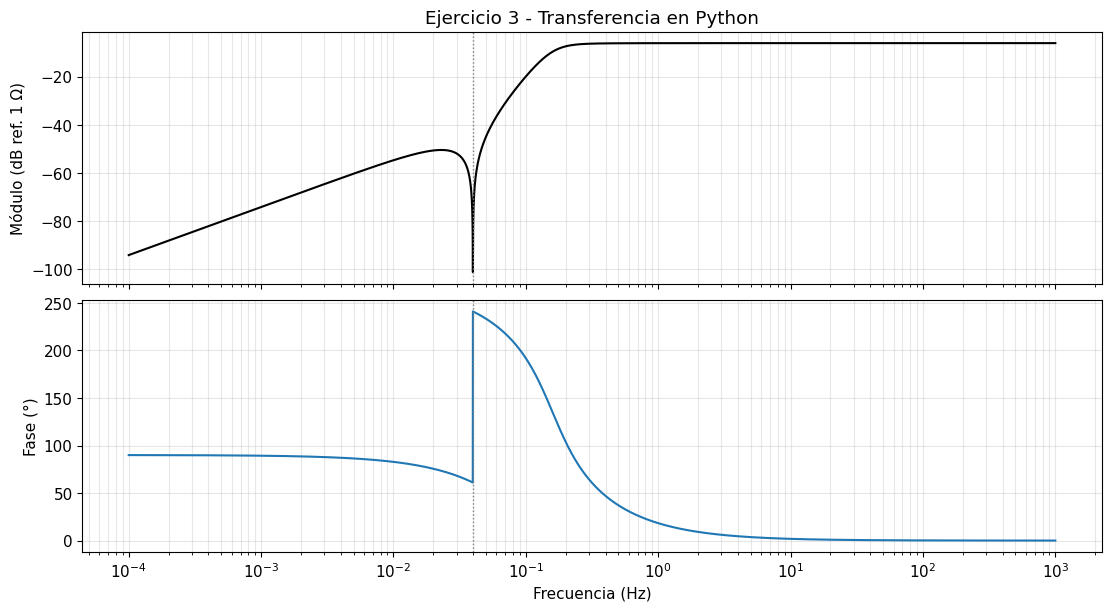

In [18]:
graficar_transferencia(3, T3, sp.Rational(1,4))

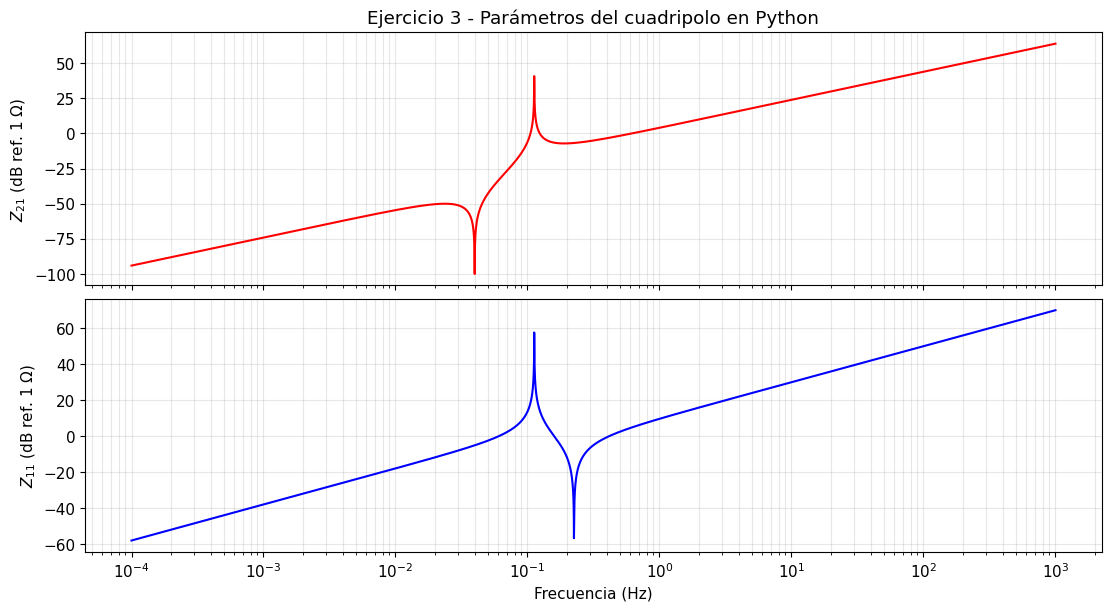

In [19]:
graficar_parametros(3, Z11_3, Z21_red3)

### <ins>Simulación en LTspice</ins>

Se simula el generador de corriente con $R_g=1\;\Omega$ en paralelo. La salida se toma sobre $L_{3B}$ y se mide `V(V2)/I(Ig)`.

<div align="center">
    <img src="./Imagenes/Ej3 Simulacion Circuito.png" alt="Circuito simulado del ejercicio 3" width="950" style="max-width:100%; height:auto;" />
</div>

#### Módulo y fase de la transimpedancia

<div align="center">
    <img src="./Imagenes/Ej3 Simulacion Modulo y Fase.png" alt="Módulo y fase de la transimpedancia del ejercicio 3 en LTspice" width="1100" style="max-width:100%; height:auto;" />
</div>

La lectura a $1\;\mathrm{kHz}$ confirma el nivel de $-6\;\mathrm{dB}$ en la meseta de alta frecuencia.

<div align="center">
    <img src="./Imagenes/Ej3 Simulacion Modulo Alta Frec.png" alt="Lectura de menos 6 dB a alta frecuencia en el ejercicio 3" width="300" style="max-width:100%; height:auto;" />
</div>

#### Parámetros del cuadripolo

Se presentan $Z_{21}$ y $Z_{11}$ del cuadripolo LC sin $R_g$, manteniendo los dos inductores del divisor de salida.

<div align="center">
    <img src="./Imagenes/Ej3 Simulacion Z21 Z11.png" alt="Z21 y Z11 del ejercicio 3 en LTspice" width="1100" style="max-width:100%; height:auto;" />
</div>

Los cursores ubican el cero de $Z_{21}$ cerca de $0{,}0398\;\mathrm{Hz}$, el polo común cerca de $0{,}1125\;\mathrm{Hz}$ y el cero de $Z_{11}$ cerca de $0{,}2251\;\mathrm{Hz}$.

<div align="center">
    <img src="./Imagenes/Ej3 Simulacion PoloCero Z21.png" alt="Lecturas de los cursores para Z21 del ejercicio 3" width="290" />
    <img src="./Imagenes/Ej3 Simulacion PoloCero Z11.png" alt="Lecturas de los cursores para Z11 del ejercicio 3" width="290" />
</div>

### <ins>Conclusión</ins>

Las curvas de Python y LTspice conservan el nulo en $f_z\approx0{,}03979\;\mathrm{Hz}$ y alcanzan una meseta de $-6\;\mathrm{dB}$ a alta frecuencia, confirmada por la lectura del cursor. El divisor inductivo mantiene $Z_{11}$ y reduce $Z_{21}$ en $6\;\mathrm{dB}$ respecto del ejercicio 1, de acuerdo con $k_3=10^{-6/20}\approx0{,}501187$. La síntesis cumple la condición de nivel adoptada para la banda de paso.

# <ins>Resolución manuscrita</ins>


In [4]:
from IPython.display import IFrame
IFrame("Imagenes/TS9.pdf", width=1000, height=700)